In [12]:
import pandas as pd

data = pd.read_csv('../Dataset/CVF Conferences Dataset.csv')

In [13]:
import re
from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

class Preprocessing:
    def __init__(self):
        self.lemmatizer = WordNetLemmatizer()
        self.stop_words = set(stopwords.words('english'))

    def cleanHTML_attribute(self, text):
        new_text = re.sub(r'[\r\n\t]', '', text)
        return BeautifulSoup(new_text, "html.parser").get_text()

    def cleanText(self, text):
        text = re.sub('https?:\/\/\S+', '', text)
        text = re.sub('[^a-zA-Z]', ' ', str(text).lower().strip())
        text = re.sub('#', '', text)
        text = re.sub('\d+', '', text)
        text = re.sub('[!"#$%&\()*+,-./:;<=>?@[\\]^_`{|}~]+', '', text)
        text = re.sub('\n', ' ', text)
        return text

    def removeStopwords(self, text):
        tokens = word_tokenize(text)
        clean_text = [self.lemmatizer.lemmatize(word) for word in tokens if word.lower() not in self.stop_words]
        return ' '.join(clean_text)

    def removeSuffix(self, text):
        text = re.sub(r'\b(\w+?)s\b', r'\1', text)
        return text

    def preprocess(self, text):
        text = self.cleanHTML_attribute(text)
        text = self.cleanText(text)
        text = self.removeStopwords(text)
        text = self.removeSuffix(text)
        return text

In [14]:
preprocessing = Preprocessing()
data['Clean Title'] = data['Title'].astype(str).apply(preprocessing.preprocess)

In [15]:
from dotenv import load_dotenv
import os

load_dotenv()
cohere_api_key = os.getenv('COHERE_API_KEY')
gemini_api_key = os.getenv('GEMINI_API_KEY')

In [16]:
# import cohere
# import numpy
# from bertopic.backend import CohereBackend

# client = cohere.Client(cohere_api_key)
# embedding_model = CohereBackend(client=client, embedding_model='embed-english-v2.0')
# response = client.embed(texts=data['Clean Title'].tolist(), model='embed-english-v2.0')
# embeddings = numpy.array(response.embeddings)

In [17]:
from sentence_transformers import SentenceTransformer

data = data.reset_index(drop=True)
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(data['Clean Title'], show_progress_bar=True)

Batches:   0%|          | 0/661 [00:00<?, ?it/s]

In [18]:
prompt = """
Based on these Keywords, determine a relevant label that accurately represents the overall topic in 5 words or fewer.
"""

In [19]:
from langchain.chains.question_answering import load_qa_chain
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(
    google_api_key=gemini_api_key,
    model="gemini-pro",
    temperature=0.6,
    topK=1,
    topP=0.6,
    convert_system_message_to_human=True
)

chain = load_qa_chain(llm, chain_type="stuff")

In [20]:
from bertopic.representation import LangChain

representation_model = LangChain(chain, prompt=prompt)

In [21]:
from transformers.pipelines import pipeline
from bertopic.representation import TextGeneration
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.vectorizers import ClassTfidfTransformer

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine')
hdbscan_model = HDBSCAN(min_cluster_size=15, metric='euclidean', cluster_selection_method='eom', prediction_data=True)
vectorizer_model = CountVectorizer(stop_words="english")
ctfidf_model = ClassTfidfTransformer()

In [22]:
from bertopic import BERTopic

topic_model = BERTopic(
    embedding_model=embedding_model,    # Step 1 - Extract embeddings
    umap_model=umap_model,              # Step 2 - Reduce dimensionality
    hdbscan_model=hdbscan_model,        # Step 3 - Cluster reduced embeddings
    vectorizer_model=vectorizer_model,  # Step 4 - Tokenize topics
    ctfidf_model=ctfidf_model,          # Step 5 - Extract topic words
    representation_model={
        'Gemini': representation_model
    },
    nr_topics=35,
    verbose=True,
)

In [23]:
topics, probs = topic_model.fit_transform(data['Clean Title'], embeddings)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
2024-06-25 20:49:11,783 - BERTopic - Reduced dimensionality
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid

In [24]:
topic_model.visualize_barchart(top_n_topics=10, n_words=10)

In [25]:
all_topics = topic_model.get_topic_info()
all_topics

,Topic,Count,Name,Representation,Gemini,Representative_Docs
0,-1,6635,-1_learning_image_object_network,"[learning, image, object, network, video, mult...","[Computer Vision and Image Processing, , , , ,...","[depth camera motion object detection, dynamic..."
1,0,1922,0_action_tracking_video_recognition,"[action, tracking, video, recognition, tempora...","[Action recognition in videos, , , , , , , , , ]","[representation flow action recognition, actio..."
2,1,1901,1_segmentation_object_semantic_shot,"[segmentation, object, semantic, shot, instanc...","[Weakly supervised instance segmentation, , , ...",[learning instance activation map weakly super...
3,2,1507,2_radiance_field_flow_stereo,"[radiance, field, flow, stereo, depth, deblurr...","[Neural Radiance Field Scene Reconstruction, ,...","[nerf neural radiance field dynamic scene, mul..."
4,3,1458,3_pose_point_estimation_cloud,"[pose, point, estimation, cloud, human, regist...","[Human pose estimation, , , , , , , , , ]","[cros view fusion human pose estimation, multi..."
5,4,1325,4_super_resolution_gan_image,"[super, resolution, gan, image, style, generat...","[Super Resolution Image Enhancement, , , , , ,...",[kernel modeling super resolution real low res...
6,5,966,5_adversarial_attack_domain_adaptation,"[adversarial, attack, domain, adaptation, labe...","[Adversarial Domain Adaptation, , , , , , , , , ]",[weighted adversarial adaptation network unsup...
7,6,635,6_shape_surface_clustering_reconstruction,"[shape, surface, clustering, reconstruction, i...","[Implicit shape modeling and reconstruction, ,...","[local deep implicit function shape, front bac..."
8,7,615,7_question_text_answering_captioning,"[question, text, answering, captioning, visual...","[Visual Question Answering, , , , , , , , , ]",[visual question generation dual task visual q...
9,8,486,8_face_facial_recognition_unit,"[face, facial, recognition, unit, forgery, lan...","[Face recognition and detection, , , , , , , ,...","[scale aware face detection, toward pose robus..."


In [26]:
gemini_labels = [re.sub(r'\W+', ' ', label[0][0].split("\n")[0].replace('"', '')) for label in topic_model.get_topics(full=True)["Gemini"].values()]
gemini_labels = [label if label else "Unlabelled" for label in gemini_labels]
all_labels = [gemini_labels[topic+topic_model._outliers] if topic != -1 else "Unlabelled" for topic in topics]

In [27]:
reduced_embeddings = UMAP(n_neighbors=10, n_components=2, min_dist=0.0, metric='cosine').fit_transform(embeddings)

In [34]:
topic_model.custom_labels_

['Computer Vision and Image Processing',
 'Action recognition in videos',
 'Weakly supervised instance segmentation',
 'Neural Radiance Field Scene Reconstruction',
 'Human pose estimation',
 'Super Resolution Image Enhancement',
 'Adversarial Domain Adaptation',
 'Implicit shape modeling and reconstruction',
 'Visual Question Answering',
 'Face recognition and detection',
 'Salient Object Detection and Segmentation',
 'Neural architecture search and network compression',
 'Cross modal hashing',
 'Knowledge distillation in machine learning',
 'Computer vision in autonomous driving',
 'Unsupervised Person Identification',
 'Anomaly detection in videos',
 'Hand pose estimation and reconstruction',
 'Avatar and fashion related computer vision',
 'LiDAR based road and object detection',
 'Audio Visual Scene Understanding',
 'Video frame interpolation',
 'Diffusion models for text image generation',
 'Human Motion Prediction',
 'Crowd counting computer vision',
 'Privacy Preserving Image Lo

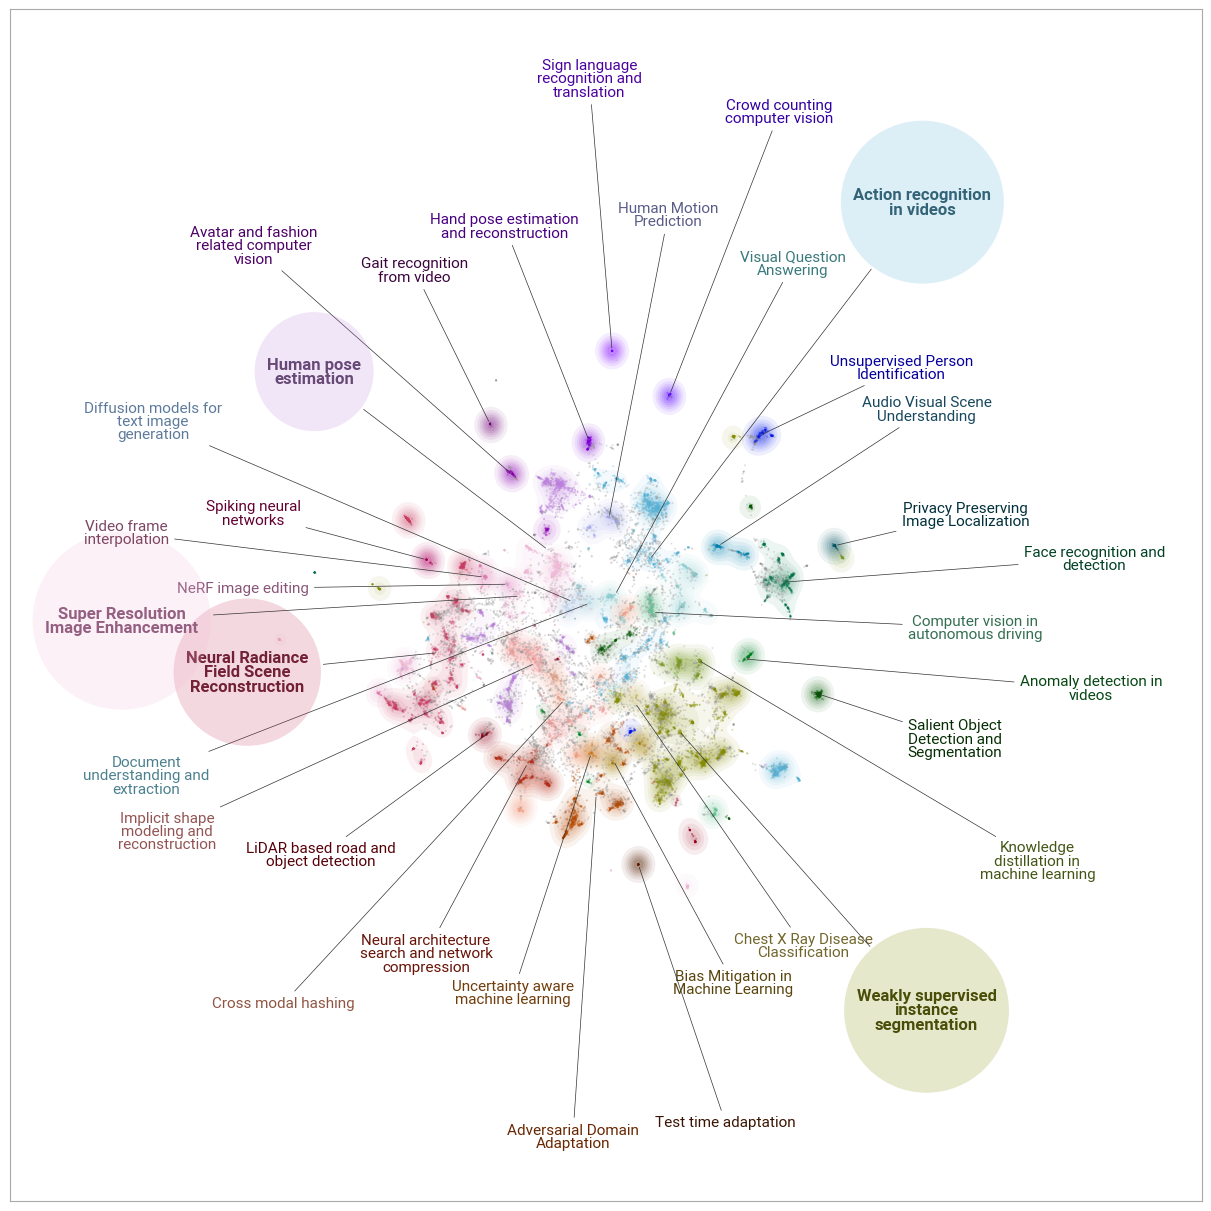

In [35]:
import datamapplot

# Run the visualization
datamapplot.create_plot(
    reduced_embeddings,
    all_labels,
    label_font_size=11,
    label_wrap_width=20,
    highlight_labels=[
        'Action recognition in videos',
        'Weakly supervised instance segmentation',
        'Neural Radiance Field Scene Reconstruction',
        'Human pose estimation',
        'Super Resolution Image Enhancement',
    ],
    highlight_label_keywords={"fontsize": 12, "fontweight": "bold", "bbox":{"boxstyle":"circle", "pad":0.75}},
    use_medoids=True,
);

  0%|          | 0/500 [00:00<?, ?it/s]

Resetting positions to accord with alignment


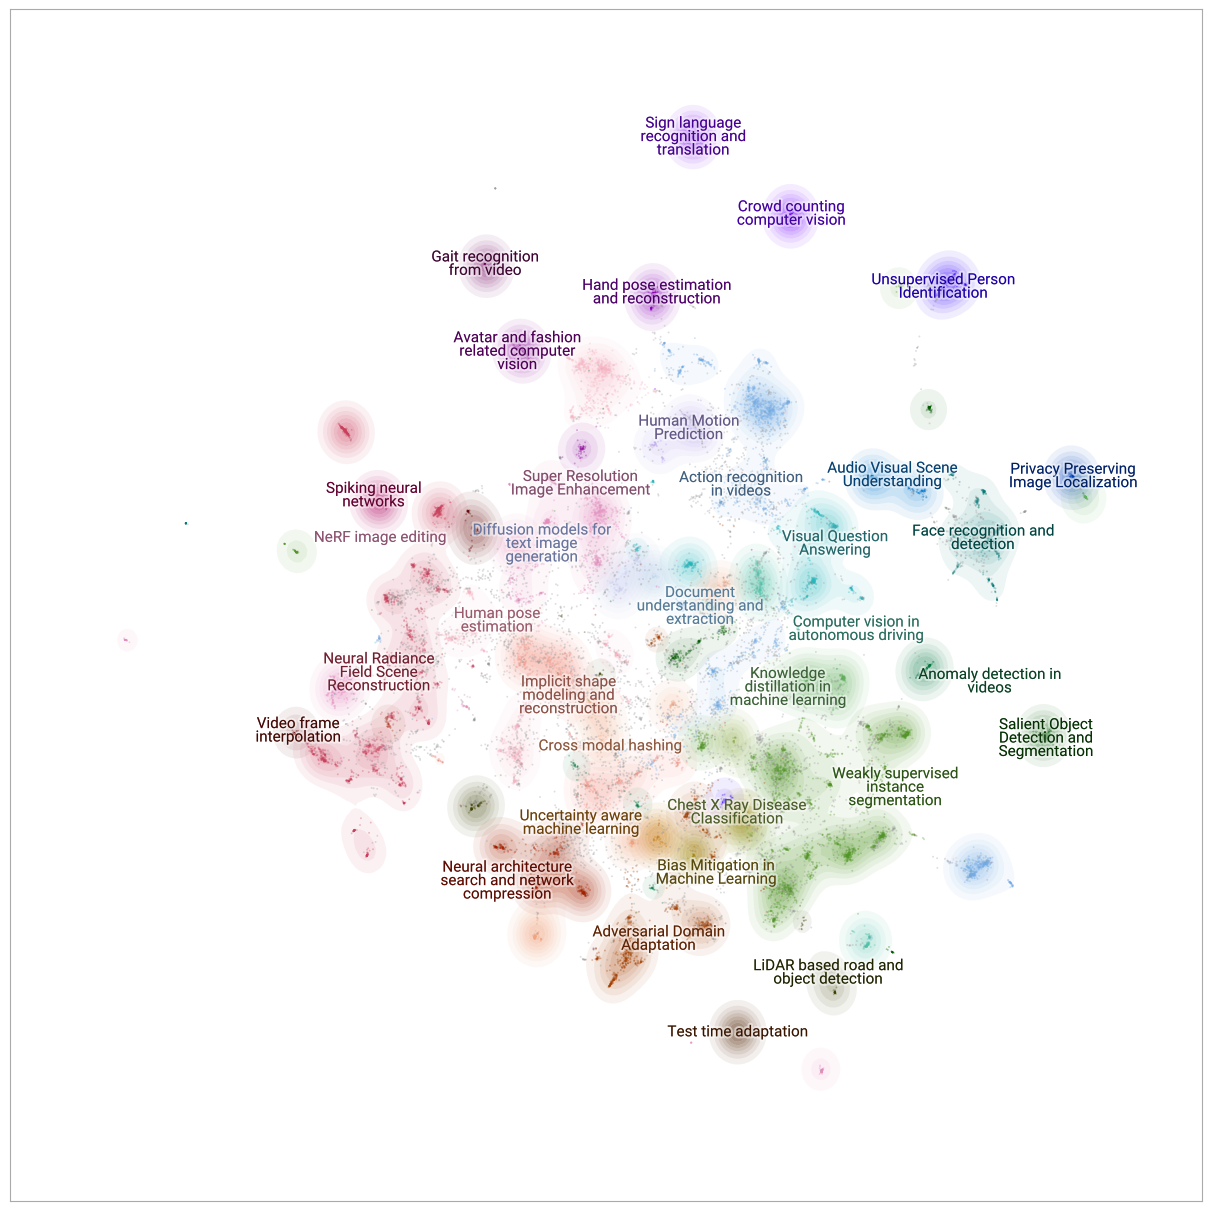

In [36]:
datamapplot.create_plot(
    reduced_embeddings,
    all_labels,
    label_font_size=11,
    label_wrap_width=20,
    use_medoids=True,
    label_over_points=True,
    dynamic_label_size=True,
);

In [29]:
data['timestamp'] = data['CVF Conferences'].str.extract(r'(\d{4})')
timestamps = data['timestamp'].to_list()

In [30]:
topic_labels_dict = {i - 1: label for i, label in enumerate(gemini_labels)}
topic_model.set_topic_labels(topic_labels_dict)

In [31]:
topics_over_time = topic_model.topics_over_time(data['Clean Title'].to_list(), timestamps)
topic_model.visualize_topics_over_time(topics_over_time, topics=[0,1,2,3,4,5,6,7,8,9], custom_labels=True, title="")

11it [00:00, 20.67it/s]


In [33]:
topics_over_time = topic_model.topics_over_time(data['Clean Title'].to_list(), timestamps)
topic_model.visualize_topics_over_time(topics_over_time, topics=[0,1,2,3,4], custom_labels=True, title="")

11it [00:00, 20.71it/s]
